# RQ2: Does the user's prompt help identify the LLM?

We compare classifiers that see three different inputs:

| Setting | Model input |
|---|---|
| **Input only** | the user's prompt (`Question`) |
| **Output only** | the LLM's response (`Answer`), same as RQ1 |
| **Input + Output** | prompt and response together |

Every setting is evaluated with the same three models (TF-IDF + Logistic
Regression, TextCNN, BiLSTM) on the **same question-grouped split**, so the
test questions are never seen in training and the settings are directly
comparable.

We also look at *why* input-only classification might work:

* **Question sharing.** How many LLMs answered each question? If every LLM
  answered the same questions, the prompt alone carries no information about
  the source.
* **Leakage check.** We repeat input-only classification on a *random* split
  (questions shared between train and test) and compare it with a lookup
  table that simply memorises "question → LLM".
* **Prompt n-grams.** The most indicative prompt words per LLM, read from the
  input-only logistic regression.

This notebook is self-contained: the data pipeline, tokeniser and models are
the same as in the RQ1 notebook.

**How to run.** In Colab, choose *Runtime → Change runtime type → GPU*, then
run all cells top to bottom. Figures and metrics are saved to `results/rq2/`.

In [1]:
import copy
import json
import random
import re
import subprocess
import sys
import time
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

try:
    import kagglehub
except ImportError:  # Colab usually ships kagglehub, but install it if missing.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

In [2]:
@dataclass
class Config:
    # --- Data ---
    dataset_handle: str = "mdsadiqiqbal/txd-22-a-large-scale-benchmark-dataset"
    csv_path: str | None = None  # Set to a local CSV path to skip the Kaggle download.
    prompt_col: str = "Question"
    response_col: str = "Answer"
    label_col: str = "Source"
    # TXD-22 also contains human-written and mixed human/AI labels.
    non_llm_label_pattern: str | None = r"(?i)human|ai-generated|ai-refined"

    # --- Class balancing ---
    min_samples_per_class: int = 500
    max_samples_per_class: int | None = 3000

    # --- Splits (fractions of the whole dataset, split by question) ---
    test_size: float = 0.15
    val_size: float = 0.15

    # --- Text preprocessing ---
    max_vocab_size: int = 50_000
    min_token_freq: int = 2
    max_prompt_tokens: int = 64  # Prompts are short.
    max_response_tokens: int = 400  # Same truncation as RQ1.

    # --- Shared neural-network hyperparameters ---
    embed_dim: int = 128
    dropout: float = 0.5
    batch_size: int = 64
    epochs: int = 10
    learning_rate: float = 1e-3
    weight_decay: float = 1e-4
    patience: int = 3  # Early stopping
    grad_clip: float = 1.0

    # --- TextCNN ---
    cnn_num_filters: int = 128
    cnn_kernel_sizes: tuple[int, ...] = (3, 4, 5)

    # --- BiLSTM ---
    lstm_hidden_dim: int = 128
    lstm_num_layers: int = 1

    # --- Misc ---
    seed: int = 42
    results_dir: str = "results/rq2"


CONFIG = Config()
RESULTS_DIR = Path(CONFIG.results_dir)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

# The three input settings compared in RQ2. Each maps to the fields fed to the model.
SETTINGS: dict[str, tuple[str, ...]] = {
    "Input only": ("prompt",),
    "Output only": ("response",),
    "Input + Output": ("prompt", "response"),
}
FIELD_COLUMNS = {"prompt": CONFIG.prompt_col, "response": CONFIG.response_col}
FIELD_MAX_TOKENS = {"prompt": CONFIG.max_prompt_tokens, "response": CONFIG.max_response_tokens}


def set_seed(seed: int) -> None:
    """Make runs reproducible across Python, NumPy and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def slugify(name: str) -> str:
    """Turn a name into a safe filename stem, e.g. 'Input + Output' -> 'input_output'."""
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")


set_seed(CONFIG.seed)

Device: cuda


## 1. Load, clean and balance the data (same pipeline as RQ1)

In [3]:
def load_raw_dataset(cfg: Config) -> pd.DataFrame:
    """Read the TXD-22 CSV from a local path or download it from Kaggle."""
    if cfg.csv_path:
        csv_file = Path(cfg.csv_path)
    else:
        download_dir = Path(kagglehub.dataset_download(cfg.dataset_handle))
        csv_file = next(download_dir.rglob("*.csv"))
    print(f"Reading {csv_file}")
    # The file contains a few invalid UTF-8 bytes; replace them instead of crashing.
    return pd.read_csv(csv_file, encoding="utf-8", encoding_errors="replace")


def clean_dataset(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    columns = [cfg.prompt_col, cfg.response_col, cfg.label_col]
    df = df[columns].dropna().copy()
    for col in columns:
        df[col] = df[col].astype(str).str.strip()
    df = df[(df[cfg.prompt_col].str.len() > 0) & (df[cfg.response_col].str.len() > 0)]

    before = len(df)
    df = df.drop_duplicates(subset=[cfg.response_col, cfg.label_col])
    df = df.drop_duplicates(subset=[cfg.response_col], keep=False)
    print(f"Removed {before - len(df):,} duplicate or ambiguous answers")
    return df.reset_index(drop=True)


def drop_non_llm_labels(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    if cfg.non_llm_label_pattern is None:
        return df
    is_non_llm = df[cfg.label_col].str.contains(cfg.non_llm_label_pattern, regex=True)
    print(f"Dropping non-LLM labels: {sorted(df.loc[is_non_llm, cfg.label_col].unique())}")
    return df[~is_non_llm].reset_index(drop=True)


def balance_classes(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    counts = df[cfg.label_col].value_counts()
    kept_labels = counts[counts >= cfg.min_samples_per_class].index
    dropped = sorted(set(counts.index) - set(kept_labels))
    if dropped:
        print(f"Dropping classes with < {cfg.min_samples_per_class} samples: {dropped}")
    df = df[df[cfg.label_col].isin(kept_labels)]

    if cfg.max_samples_per_class is not None:
        shuffled = df.sample(frac=1, random_state=cfg.seed)
        df = shuffled.groupby(cfg.label_col).head(cfg.max_samples_per_class)
    return df.reset_index(drop=True)


raw_df = load_raw_dataset(CONFIG)
data_df = balance_classes(drop_non_llm_labels(clean_dataset(raw_df, CONFIG), CONFIG), CONFIG)
print(f"Final dataset: {len(data_df):,} answers, "
      f"{data_df[CONFIG.label_col].nunique()} LLMs, "
      f"{data_df[CONFIG.prompt_col].nunique():,} unique questions")

Using Colab cache for faster access to the 'txd-22-a-large-scale-benchmark-dataset' dataset.
Reading /kaggle/input/txd-22-a-large-scale-benchmark-dataset/TXD-22 A Large-Scale Benchmark Dataset.csv
Removed 48 duplicate or ambiguous answers
Dropping non-LLM labels: ['AI-generated and AI-refined', 'AI-generated and AI-refined and Human-written', 'AI-generated�and Human-written', 'Human written', 'Human-written and AI-refined']
Final dataset: 50,980 answers, 17 LLMs, 3,076 unique questions


## 2. How are questions shared between LLMs?

This is the key fact for interpreting input-only results. If every question
was sent to every LLM, the prompt cannot reveal the source on unseen
questions. If each LLM got its *own* questions (different topics, phrasing or
templates), the prompt alone can identify the source, but that reflects how
the dataset was collected, not an LLM fingerprint.

LLMs that answered each question:
count    3076.00
mean       16.55
std         2.30
min         1.00
25%        17.00
50%        17.00
75%        17.00
max        17.00

Questions answered by exactly one LLM: 0.1%
Questions answered by all 17 LLMs: 93.9%

Unique questions per LLM:
Source
BLACKBOXAI    2987
Gemma         2988
Llama         2988
Grok          2988
Perplexity    2988
Nova          2988
DeepAI        2991
Gemini        2992
Poe           2996
ChatGPT       2996
DeepSeek      2997
Copilot       3000
Claude        3000
Mistral AI    3000
Pi            3000
Qwen          3000
Z.ai          3000

Prompt length (words) per LLM:
            mean  50%  std
Source                    
BLACKBOXAI   6.4  6.0  2.4
ChatGPT      6.4  6.0  2.4
Claude       6.4  6.0  2.4
Copilot      6.4  6.0  2.4
DeepSeek     6.4  6.0  2.4
Gemini       6.4  6.0  2.4
Gemma        6.4  6.0  2.4
Grok         6.4  6.0  2.4
Perplexity   6.4  6.0  2.4
Llama        6.4  6.0  2.4
Mistral AI   6.4  6.0  2.4
Nova

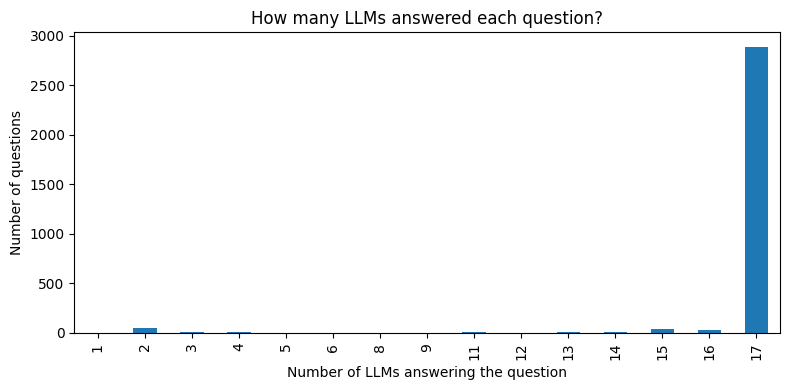

In [4]:
sources_per_question = data_df.groupby(CONFIG.prompt_col)[CONFIG.label_col].nunique()
questions_per_source = data_df.groupby(CONFIG.label_col)[CONFIG.prompt_col].nunique()
num_sources = data_df[CONFIG.label_col].nunique()

print("LLMs that answered each question:")
print(sources_per_question.describe().round(2).to_string())
print(f"\nQuestions answered by exactly one LLM: {(sources_per_question == 1).mean():.1%}")
print(f"Questions answered by all {num_sources} LLMs: "
      f"{(sources_per_question == num_sources).mean():.1%}")
print("\nUnique questions per LLM:")
print(questions_per_source.sort_values().to_string())

prompt_word_counts = data_df[CONFIG.prompt_col].str.split().str.len()
prompt_length_stats = prompt_word_counts.groupby(data_df[CONFIG.label_col]).describe()[
    ["mean", "50%", "std"]
].round(1).sort_values("mean")
print("\nPrompt length (words) per LLM:")
print(prompt_length_stats.to_string())

sharing_stats = pd.DataFrame({
    "unique_questions": questions_per_source,
    "mean_prompt_words": prompt_length_stats["mean"],
})
sharing_stats.to_csv(RESULTS_DIR / "question_sharing_by_llm.csv")

fig, ax = plt.subplots(figsize=(8, 4))
sources_per_question.value_counts().sort_index().plot.bar(ax=ax)
ax.set(title="How many LLMs answered each question?",
       xlabel="Number of LLMs answering the question", ylabel="Number of questions")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "sources_per_question.png", dpi=150)
plt.show()

## 3. Train / validation / test split (grouped by question)

Identical to RQ1: `StratifiedGroupKFold` keeps every answer to a question in
the same split. The same split is used for all three settings.

In [5]:
def grouped_split(
    df: pd.DataFrame, holdout_frac: float, cfg: Config
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Split off roughly `holdout_frac` of rows with no question shared between parts."""
    n_splits = max(2, round(1 / holdout_frac))
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=cfg.seed)
    keep_idx, holdout_idx = next(
        splitter.split(df, df[cfg.label_col], groups=df[cfg.prompt_col])
    )
    return df.iloc[keep_idx].reset_index(drop=True), df.iloc[holdout_idx].reset_index(drop=True)


train_val_df, test_df = grouped_split(data_df, CONFIG.test_size, CONFIG)
val_frac_of_remaining = CONFIG.val_size / (1 - CONFIG.test_size)
train_df, val_df = grouped_split(train_val_df, val_frac_of_remaining, CONFIG)

train_q, val_q, test_q = (set(d[CONFIG.prompt_col]) for d in (train_df, val_df, test_df))
assert not (train_q & val_q) and not (train_q & test_q) and not (val_q & test_q)

for name, split in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:>5}: {len(split):6,} answers ({len(split) / len(data_df):.1%}), "
          f"{split[CONFIG.prompt_col].nunique():,} questions")

CLASS_NAMES = sorted(data_df[CONFIG.label_col].unique())
LABEL_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
y_train = train_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
y_val = val_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
y_test = test_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()

train: 36,369 answers (71.3%), 2,197 questions
  val:  7,296 answers (14.3%), 439 questions
 test:  7,315 answers (14.3%), 440 questions


## 4. Evaluation helpers

Each result is stored as one row (setting, model, metrics). Confusion matrices
are saved to `results/rq2/` rather than displayed, to keep the notebook short.

In [6]:
RESULTS: list[dict] = []


def evaluate_predictions(
    setting: str, model_name: str, y_true: np.ndarray, y_pred: np.ndarray, **extra
) -> None:
    """Print headline metrics, save the report and confusion matrix, record the result."""
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    print(f"=== {setting} | {model_name} | test accuracy {accuracy:.4f} | "
          f"macro-F1 {macro_f1:.4f} ===")

    slug = slugify(f"{setting}_{model_name}")
    report = classification_report(
        y_true, y_pred, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES,
        digits=3, zero_division=0,
    )
    (RESULTS_DIR / f"report_{slug}.txt").write_text(report)

    fig, ax = plt.subplots(figsize=(11, 9))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=range(len(CLASS_NAMES)), display_labels=CLASS_NAMES,
        normalize="true", values_format=".2f", xticks_rotation=90,
        cmap="Blues", ax=ax, text_kw={"fontsize": 6},
    )
    ax.set_title(f"{model_name} on {setting}: normalised confusion matrix (test set)")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f"confusion_{slug}.png", dpi=150)
    plt.close(fig)

    RESULTS.append({
        "setting": setting, "model": model_name,
        "accuracy": accuracy, "macro_f1": macro_f1, **extra,
    })

## 5. Baselines: majority class and TF-IDF + Logistic Regression

For **Input + Output**, the prompt and the response get *separate* TF-IDF
vectorisers whose features are concatenated, so "word X in the prompt" and
"word X in the response" are different features.

In [7]:
majority = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
majority_pred = majority.predict(np.zeros((len(y_test), 1)))
for setting in SETTINGS:
    evaluate_predictions(setting, "Majority class", y_test, majority_pred)


def make_tfidf_features(
    fields: tuple[str, ...], fit_df: pd.DataFrame, transform_df: pd.DataFrame
) -> tuple[sp.csr_matrix, sp.csr_matrix, list[TfidfVectorizer]]:
    """Fit one TF-IDF vectoriser per field on `fit_df` and stack the field features."""
    vectorizers, fit_parts, transform_parts = [], [], []
    for field in fields:
        column = FIELD_COLUMNS[field]
        vectorizer = TfidfVectorizer(
            ngram_range=(1, 2), max_features=100_000, min_df=2, sublinear_tf=True
        )
        fit_parts.append(vectorizer.fit_transform(fit_df[column]))
        transform_parts.append(vectorizer.transform(transform_df[column]))
        vectorizers.append(vectorizer)
    return sp.hstack(fit_parts).tocsr(), sp.hstack(transform_parts).tocsr(), vectorizers


tfidf_models: dict[str, tuple[LogisticRegression, list[TfidfVectorizer]]] = {}
for setting, fields in SETTINGS.items():
    start = time.time()
    X_train, X_test, vectorizers = make_tfidf_features(fields, train_df, test_df)
    log_reg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
    evaluate_predictions(
        setting, "TF-IDF + LogReg", y_test, log_reg.predict(X_test),
        train_seconds=round(time.time() - start, 1),
    )
    tfidf_models[setting] = (log_reg, vectorizers)

=== Input only | Majority class | test accuracy 0.0584 | macro-F1 0.0065 ===
=== Output only | Majority class | test accuracy 0.0584 | macro-F1 0.0065 ===
=== Input + Output | Majority class | test accuracy 0.0584 | macro-F1 0.0065 ===
=== Input only | TF-IDF + LogReg | test accuracy 0.0576 | macro-F1 0.0381 ===
=== Output only | TF-IDF + LogReg | test accuracy 0.7290 | macro-F1 0.7230 ===
=== Input + Output | TF-IDF + LogReg | test accuracy 0.7187 | macro-F1 0.7123 ===


### Which prompt words point to which LLM?

The largest input-only logistic-regression weights per LLM. If these are
topic words (e.g. "network", "recipe") the input-only signal comes from
*which questions each LLM was asked*, a property of dataset collection.

In [8]:
input_only_model, (prompt_vectorizer,) = tfidf_models["Input only"]
feature_names = prompt_vectorizer.get_feature_names_out()
top_ngrams = {
    CLASS_NAMES[class_id]: ", ".join(feature_names[np.argsort(weights)[::-1][:8]])
    for class_id, weights in enumerate(input_only_model.coef_)
}
top_ngrams_df = pd.Series(top_ngrams, name="top prompt n-grams").to_frame()
top_ngrams_df.to_csv(RESULTS_DIR / "top_prompt_ngrams_by_llm.csv")
print(top_ngrams_df.to_string())

                                                                                                   top prompt n-grams
BLACKBOXAI           is vector, vector editing, vector, maxwell equations, equations, maxwell, are maxwell, the polis
ChatGPT                                   women human, the fourth, fourth, wall, fourth wall, are women, law kcl, kcl
Claude                       law, lenz, is lenz, lenz law, explain machiavelli, views on, machiavelli views, on power
Copilot                               law, lenz, lenz law, is lenz, machiavelli, explain machiavelli, views, views on
DeepAI        migration, define migration, and types, of migration, history of, the history, kirchhoff, migration and
DeepSeek                        law, lenz law, lenz, is lenz, machiavelli views, views on, explain machiavelli, views
Gemini                                     law, lenz, lenz law, is lenz, machiavelli views, views on, on power, views
Gemma                    is vector, vector editing, vect

## 6. Tokenisation for the neural models

Same tokeniser as RQ1. For **Input + Output** the model sees
`prompt tokens <sep> response tokens`. The prompt is capped at
`max_prompt_tokens` and the response at `max_response_tokens`, so the response
part is identical to the Output-only setting.

In [9]:
TOKEN_PATTERN = re.compile(r"\n|\w+|[^\w\s]")
NEWLINE_TOKEN = "<nl>"
SEP_TOKEN = "<sep>"


def tokenize(text: str) -> list[str]:
    text = text.replace("\r\n", "\n").lower()
    return [NEWLINE_TOKEN if tok == "\n" else tok for tok in TOKEN_PATTERN.findall(text)]


class Vocabulary:
    PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"
    PAD_ID, UNK_ID = 0, 1

    def __init__(self, tokenized_texts: list[list[str]], max_size: int, min_freq: int):
        counter = Counter(tok for tokens in tokenized_texts for tok in tokens)
        frequent = [tok for tok, freq in counter.most_common(max_size - 2) if freq >= min_freq]
        self.id_to_token = [self.PAD_TOKEN, self.UNK_TOKEN] + frequent
        self.token_to_id = {tok: i for i, tok in enumerate(self.id_to_token)}

    def __len__(self) -> int:
        return len(self.id_to_token)

    def encode(self, tokens: list[str]) -> list[int]:
        return [self.token_to_id.get(tok, self.UNK_ID) for tok in tokens]


def build_sequences(df: pd.DataFrame, fields: tuple[str, ...]) -> list[list[str]]:
    """Join the (truncated) token lists of `fields`, separated by SEP_TOKEN."""
    sequences = []
    for field_tokens in zip(*(df[f"{field}_tokens"] for field in fields)):
        sequence = []
        for i, (field, tokens) in enumerate(zip(fields, field_tokens)):
            if i > 0:
                sequence.append(SEP_TOKEN)
            sequence.extend(tokens[: FIELD_MAX_TOKENS[field]])
        sequences.append(sequence)
    return sequences


def build_tensor_dataset(
    sequences: list[list[str]], labels: np.ndarray, vocab: Vocabulary, max_len: int
) -> TensorDataset:
    """Encode token sequences as a padded (N, max_len) id matrix plus lengths and labels."""
    token_ids = torch.full((len(sequences), max_len), Vocabulary.PAD_ID, dtype=torch.long)
    lengths = torch.empty(len(sequences), dtype=torch.long)
    for row, tokens in enumerate(sequences):
        ids = vocab.encode(tokens[:max_len]) or [Vocabulary.UNK_ID]
        token_ids[row, : len(ids)] = torch.tensor(ids)
        lengths[row] = len(ids)
    return TensorDataset(token_ids, lengths, torch.as_tensor(labels, dtype=torch.long))


# Tokenise each field once; every setting reuses these columns.
for split in (train_df, val_df, test_df):
    for field, column in FIELD_COLUMNS.items():
        split[f"{field}_tokens"] = split[column].map(tokenize)

prompt_lengths = train_df["prompt_tokens"].str.len()
print(f"Prompt tokens: median {prompt_lengths.median():.0f}, max {prompt_lengths.max()}; "
      f"{(prompt_lengths > CONFIG.max_prompt_tokens).mean():.1%} truncated "
      f"at {CONFIG.max_prompt_tokens}")


def make_loaders(fields: tuple[str, ...]) -> tuple[DataLoader, DataLoader, DataLoader, int]:
    """Build the vocabulary and data loaders for one input setting."""
    max_len = sum(FIELD_MAX_TOKENS[f] for f in fields) + len(fields) - 1
    train_seqs = build_sequences(train_df, fields)
    vocab = Vocabulary(train_seqs, CONFIG.max_vocab_size, CONFIG.min_token_freq)

    datasets = [
        build_tensor_dataset(train_seqs, y_train, vocab, max_len),
        build_tensor_dataset(build_sequences(val_df, fields), y_val, vocab, max_len),
        build_tensor_dataset(build_sequences(test_df, fields), y_test, vocab, max_len),
    ]
    loader_kwargs = {"batch_size": CONFIG.batch_size, "pin_memory": DEVICE.type == "cuda"}
    train_loader = DataLoader(
        datasets[0], shuffle=True,
        generator=torch.Generator().manual_seed(CONFIG.seed), **loader_kwargs,
    )
    val_loader = DataLoader(datasets[1], shuffle=False, **loader_kwargs)
    test_loader = DataLoader(datasets[2], shuffle=False, **loader_kwargs)
    return train_loader, val_loader, test_loader, len(vocab)

Prompt tokens: median 8, max 418; 0.0% truncated at 64


## 7. Models (identical to RQ1)

In [10]:
class TextCNN(nn.Module):
    def __init__(
        self, vocab_size: int, embed_dim: int, num_classes: int,
        num_filters: int, kernel_sizes: tuple[int, ...], dropout: float,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=Vocabulary.PAD_ID)
        self.convs = nn.ModuleList(
            nn.Conv1d(embed_dim, num_filters, kernel_size=k) for k in kernel_sizes
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * len(kernel_sizes), num_classes)

    def forward(self, token_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        # Conv1d expects (batch, channels, seq_len).
        embedded = self.embedding(token_ids).transpose(1, 2)
        pooled = [F.relu(conv(embedded)).max(dim=2).values for conv in self.convs]
        return self.classifier(self.dropout(torch.cat(pooled, dim=1)))


class BiLSTMClassifier(nn.Module):
    def __init__(
        self, vocab_size: int, embed_dim: int, num_classes: int,
        hidden_dim: int, num_layers: int, dropout: float,
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=Vocabulary.PAD_ID)
        self.lstm = nn.LSTM(
            embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
            bidirectional=True, dropout=dropout if num_layers > 1 else 0.0,
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(2 * hidden_dim, num_classes)

    def forward(self, token_ids: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.dropout(self.embedding(token_ids))
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        # hidden: (num_layers * 2, batch, hidden_dim); take the top layer's two directions.
        final_state = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.classifier(self.dropout(final_state))


def build_model(model_name: str, vocab_size: int) -> nn.Module:
    if model_name == "TextCNN":
        return TextCNN(
            vocab_size=vocab_size, embed_dim=CONFIG.embed_dim, num_classes=len(CLASS_NAMES),
            num_filters=CONFIG.cnn_num_filters, kernel_sizes=CONFIG.cnn_kernel_sizes,
            dropout=CONFIG.dropout,
        )
    if model_name == "BiLSTM":
        return BiLSTMClassifier(
            vocab_size=vocab_size, embed_dim=CONFIG.embed_dim, num_classes=len(CLASS_NAMES),
            hidden_dim=CONFIG.lstm_hidden_dim, num_layers=CONFIG.lstm_num_layers,
            dropout=CONFIG.dropout,
        )
    raise ValueError(f"Unknown model: {model_name}")


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## 8. Training loop (identical to RQ1)

Cross-entropy loss, AdamW, gradient clipping, early stopping on validation
macro-F1 with the best epoch's weights restored.

In [11]:
def run_epoch(
    model: nn.Module, loader: DataLoader, criterion: nn.Module,
    optimizer: torch.optim.Optimizer | None = None, grad_clip: float | None = None,
) -> tuple[float, np.ndarray, np.ndarray]:
    """One pass over `loader`. Trains if an optimizer is given, else evaluates.

    Returns (mean loss, predictions, true labels).
    """
    is_training = optimizer is not None
    model.train(is_training)
    total_loss, all_preds, all_labels = 0.0, [], []

    with torch.set_grad_enabled(is_training):
        for token_ids, lengths, labels in loader:
            token_ids, labels = token_ids.to(DEVICE), labels.to(DEVICE)
            logits = model(token_ids, lengths)
            loss = criterion(logits, labels)

            if is_training:
                optimizer.zero_grad()
                loss.backward()
                if grad_clip:
                    nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()

            total_loss += loss.item() * len(labels)
            all_preds.append(logits.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())

    preds = torch.cat(all_preds).numpy()
    true = torch.cat(all_labels).numpy()
    return total_loss / len(true), preds, true


def train_model(
    model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, cfg: Config
) -> tuple[nn.Module, pd.DataFrame, float]:
    """Train with early stopping and return (best model, per-epoch history, seconds)."""
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay
    )

    history = []
    best_f1, best_state, epochs_without_improvement = -1.0, None, 0
    start = time.time()

    for epoch in range(1, cfg.epochs + 1):
        epoch_start = time.time()
        train_loss, train_pred, train_true = run_epoch(
            model, train_loader, criterion, optimizer, cfg.grad_clip
        )
        val_loss, val_pred, val_true = run_epoch(model, val_loader, criterion)

        row = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_acc": accuracy_score(train_true, train_pred),
            "val_acc": accuracy_score(val_true, val_pred),
            "val_macro_f1": f1_score(val_true, val_pred, average="macro"),
        }
        history.append(row)
        print(f"  epoch {epoch:2d} | train loss {train_loss:.4f} acc {row['train_acc']:.4f} | "
              f"val loss {val_loss:.4f} acc {row['val_acc']:.4f} "
              f"F1 {row['val_macro_f1']:.4f} | {time.time() - epoch_start:.0f}s")

        if row["val_macro_f1"] > best_f1:
            best_f1 = row["val_macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= cfg.patience:
                print(f"  Early stopping: no improvement for {cfg.patience} epochs.")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), time.time() - start

## 9. Train TextCNN and BiLSTM on every input setting

3 settings × 2 models = 6 training runs. Output-only and Input + Output are
the slow ones; Input-only trains in seconds because prompts are short.

In [12]:
HISTORIES: dict[str, pd.DataFrame] = {}

for setting, fields in SETTINGS.items():
    train_loader, val_loader, test_loader, vocab_size = make_loaders(fields)
    print(f"\n########## {setting}: vocabulary {vocab_size:,} ##########")

    for model_name in ("TextCNN", "BiLSTM"):
        set_seed(CONFIG.seed)
        model = build_model(model_name, vocab_size)
        num_params = count_parameters(model)
        print(f"\n--- {model_name} ({num_params:,} parameters) ---")

        model, history, seconds = train_model(model, train_loader, val_loader, CONFIG)
        HISTORIES[f"{setting} | {model_name}"] = history
        history.to_csv(RESULTS_DIR / f"history_{slugify(setting)}_{slugify(model_name)}.csv",
                       index=False)

        _, test_pred, test_true = run_epoch(model, test_loader, nn.CrossEntropyLoss())
        evaluate_predictions(
            setting, model_name, test_true, test_pred,
            parameters=num_params, train_seconds=round(seconds, 1),
            best_epoch=int(history["val_macro_f1"].idxmax()) + 1,
        )


########## Input only: vocabulary 2,718 ##########

--- TextCNN (551,441 parameters) ---
  epoch  1 | train loss 2.9482 acc 0.0446 | val loss 2.8446 acc 0.0599 F1 0.0372 | 5s
  epoch  2 | train loss 2.8700 acc 0.0456 | val loss 2.8339 acc 0.0595 F1 0.0339 | 2s
  epoch  3 | train loss 2.8497 acc 0.0481 | val loss 2.8307 acc 0.0599 F1 0.0409 | 3s
  epoch  4 | train loss 2.8379 acc 0.0484 | val loss 2.8296 acc 0.0600 F1 0.0260 | 3s
  epoch  5 | train loss 2.8342 acc 0.0516 | val loss 2.8302 acc 0.0600 F1 0.0250 | 2s
  epoch  6 | train loss 2.8317 acc 0.0552 | val loss 2.8308 acc 0.0600 F1 0.0242 | 2s
  Early stopping: no improvement for 3 epochs.
=== Input only | TextCNN | test accuracy 0.0596 | macro-F1 0.0416 ===

--- BiLSTM (616,465 parameters) ---
  epoch  1 | train loss 2.8433 acc 0.0583 | val loss 2.8344 acc 0.0591 F1 0.0275 | 4s
  epoch  2 | train loss 2.8377 acc 0.0566 | val loss 2.8338 acc 0.0583 F1 0.0185 | 4s
  epoch  3 | train loss 2.8359 acc 0.0570 | val loss 2.8337 acc 0.05

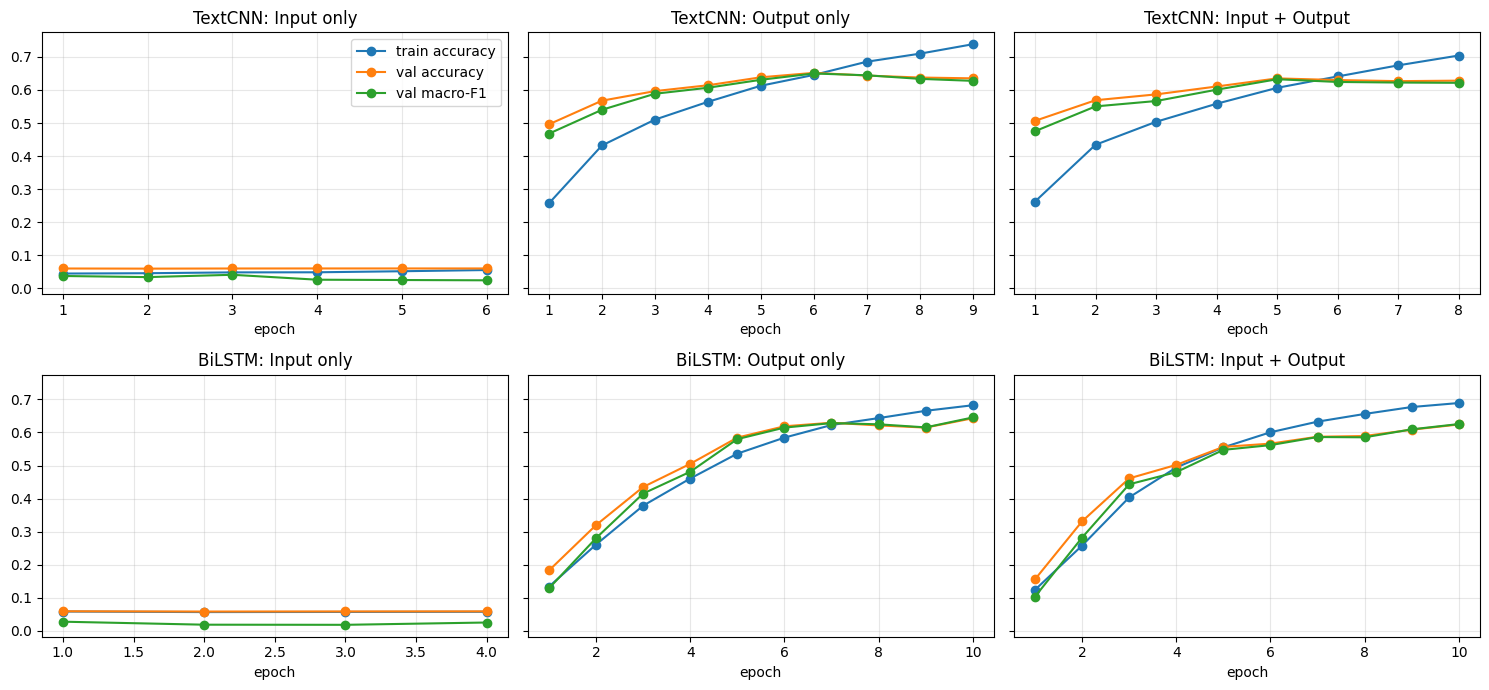

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for col, setting in enumerate(SETTINGS):
    for row, model_name in enumerate(("TextCNN", "BiLSTM")):
        history = HISTORIES[f"{setting} | {model_name}"]
        ax = axes[row, col]
        ax.plot(history["epoch"], history["train_acc"], marker="o", label="train accuracy")
        ax.plot(history["epoch"], history["val_acc"], marker="o", label="val accuracy")
        ax.plot(history["epoch"], history["val_macro_f1"], marker="o", label="val macro-F1")
        ax.set_title(f"{model_name}: {setting}")
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_curves.png", dpi=150)
plt.show()

## 10. Results: Input only vs Output only vs Input + Output


Test accuracy:
setting          Input only  Output only  Input + Output
model                                                   
Majority class       0.0584       0.0584          0.0584
TF-IDF + LogReg      0.0576       0.7290          0.7187
TextCNN              0.0596       0.6431          0.6366
BiLSTM               0.0593       0.6427          0.6261

Test macro_f1:
setting          Input only  Output only  Input + Output
model                                                   
Majority class       0.0065       0.0065          0.0065
TF-IDF + LogReg      0.0381       0.7230          0.7123
TextCNN              0.0416       0.6395          0.6340
BiLSTM               0.0281       0.6453          0.6276

Macro-F1 change from adding the prompt (Input + Output minus Output only):
model
TF-IDF + LogReg   -0.0107
TextCNN           -0.0055
BiLSTM            -0.0177


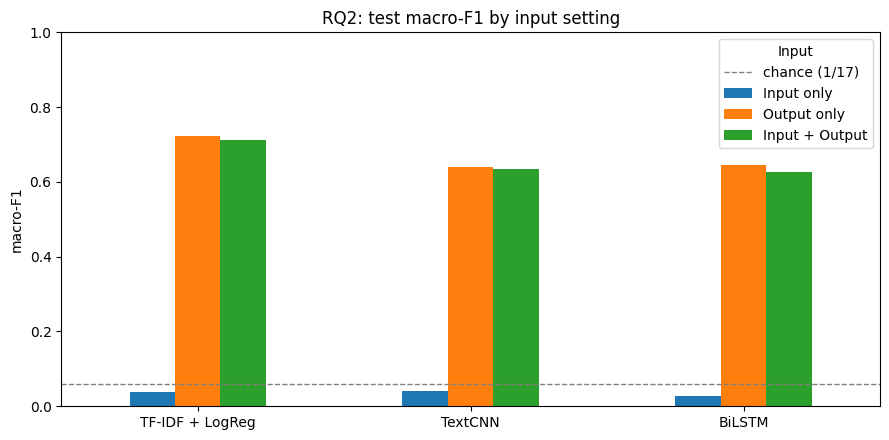

In [14]:
results_df = pd.DataFrame(RESULTS)
results_df.to_csv(RESULTS_DIR / "rq2_results_long.csv", index=False)

model_order = ["Majority class", "TF-IDF + LogReg", "TextCNN", "BiLSTM"]
setting_order = list(SETTINGS)
summary = {}
for metric in ("accuracy", "macro_f1"):
    table = results_df.pivot(index="model", columns="setting", values=metric)
    summary[metric] = table.loc[model_order, setting_order].round(4)
    summary[metric].to_csv(RESULTS_DIR / f"rq2_{metric}.csv")
    print(f"\nTest {metric}:")
    print(summary[metric].to_string())

# Q(ii): does adding the prompt to the response help?
gain = (summary["macro_f1"]["Input + Output"] - summary["macro_f1"]["Output only"]).round(4)
print("\nMacro-F1 change from adding the prompt (Input + Output minus Output only):")
print(gain.drop("Majority class").to_string())

fig, ax = plt.subplots(figsize=(9, 4.5))
summary["macro_f1"].drop("Majority class").plot.bar(ax=ax, rot=0)
chance = 1 / len(CLASS_NAMES)
ax.axhline(chance, color="grey", linestyle="--", linewidth=1, label=f"chance (1/{len(CLASS_NAMES)})")
ax.set(title="RQ2: test macro-F1 by input setting", ylabel="macro-F1", xlabel="", ylim=(0, 1))
ax.legend(title="Input")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "rq2_macro_f1.png", dpi=150)
plt.show()

## 11. Leakage check: input-only on a *random* split

Here train and test may share questions. We compare two input-only models:

* **TF-IDF + LogReg** on the prompt.
* **Question lookup**: for each test prompt, predict the LLM that answered
  that exact prompt most often in training (majority class if unseen).

If input-only accuracy is much higher here than on the grouped split, the
prompt only "identifies" the LLM through memorised question-to-LLM
assignments in the dataset, not through anything generalisable.

In [15]:
rand_train_df, rand_test_df = train_test_split(
    data_df, test_size=CONFIG.test_size, stratify=data_df[CONFIG.label_col],
    random_state=CONFIG.seed,
)
y_rand_train = rand_train_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
y_rand_test = rand_test_df[CONFIG.label_col].map(LABEL_TO_ID).to_numpy()
seen_share = rand_test_df[CONFIG.prompt_col].isin(set(rand_train_df[CONFIG.prompt_col])).mean()
print(f"Random split: {seen_share:.1%} of test prompts also appear in training")

X_rand_train, X_rand_test, _ = make_tfidf_features(("prompt",), rand_train_df, rand_test_df)
rand_log_reg = LogisticRegression(max_iter=1000).fit(X_rand_train, y_rand_train)
rand_tfidf_pred = rand_log_reg.predict(X_rand_test)

most_common_label = Counter(y_rand_train).most_common(1)[0][0]
question_to_label = (
    pd.Series(y_rand_train, index=rand_train_df[CONFIG.prompt_col].to_numpy())
    .groupby(level=0).agg(lambda labels: labels.value_counts().idxmax())
)
lookup_pred = (
    rand_test_df[CONFIG.prompt_col].map(question_to_label)
    .fillna(most_common_label).astype(int).to_numpy()
)

grouped_input_only = results_df.query("setting == 'Input only' and model == 'TF-IDF + LogReg'")
leakage = pd.DataFrame([
    {"split": "grouped by question", "model": "TF-IDF + LogReg",
     "accuracy": grouped_input_only["accuracy"].item(),
     "macro_f1": grouped_input_only["macro_f1"].item()},
    {"split": "random", "model": "TF-IDF + LogReg",
     "accuracy": accuracy_score(y_rand_test, rand_tfidf_pred),
     "macro_f1": f1_score(y_rand_test, rand_tfidf_pred, average="macro")},
    {"split": "random", "model": "Question lookup",
     "accuracy": accuracy_score(y_rand_test, lookup_pred),
     "macro_f1": f1_score(y_rand_test, lookup_pred, average="macro")},
]).round(4)
leakage.to_csv(RESULTS_DIR / "rq2_leakage_check.csv", index=False)
print("\nInput-only classification, grouped vs random split:")
print(leakage.to_string(index=False))

Random split: 99.9% of test prompts also appear in training

Input-only classification, grouped vs random split:
              split           model  accuracy  macro_f1
grouped by question TF-IDF + LogReg    0.0576    0.0381
             random TF-IDF + LogReg    0.0003    0.0002
             random Question lookup    0.0000    0.0000


## 12. Save run information

**Reading the results for the report**

* **(i) Can the LLM be predicted from the prompt alone?** Compare the
  Input-only row with chance (`1 / number of LLMs`) and the majority baseline.
* **(ii) Does including the input help?** Use the "Input + Output minus
  Output only" table. A gain near zero means the response already carries
  the signal.
* **(iii) If input-only works surprisingly well, why?** Use the question-
  sharing statistics (section 2), the top prompt n-grams (section 5) and the
  leakage check (section 11). High input-only scores on unseen questions mean
  each LLM was given different kinds of questions when the dataset was
  built. High scores only on the random split mean memorised question → LLM
  assignments.

In [16]:
run_info = {
    "config": asdict(CONFIG),
    "settings": {name: list(fields) for name, fields in SETTINGS.items()},
    "classes": CLASS_NAMES,
    "split_sizes": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "device": str(DEVICE),
    "results": RESULTS,
    "leakage_check": leakage.to_dict(orient="records"),
}
(RESULTS_DIR / "rq2_run_info.json").write_text(json.dumps(run_info, indent=2, default=str))
print(f"All outputs saved to {RESULTS_DIR.resolve()}")

All outputs saved to /content/results/rq2
